no data file found, using the demo data
(40269, 8)
  invoice stock_code description  quantity        invoice_date  price  \
0  507851       POST     POSTAGE         1 2010-01-01 09:53:00  18.00   
1  507851      10007  ITEM 10007         4 2010-01-01 09:53:00   2.25   
2  508522      10136  ITEM 10136         5 2010-01-01 13:04:00   3.28   
3  508522      10247  ITEM 10247         4 2010-01-01 13:04:00   8.18   
4  508522      10115  ITEM 10115         5 2010-01-01 13:04:00   1.98   

   customer_id         country  
0          NaN  United Kingdom  
1          NaN  United Kingdom  
2          NaN  United Kingdom  
3          NaN  United Kingdom  
4          NaN  United Kingdom  

--- validation log ---
                                               issue  rows                                         treatment
                                exact duplicate rows    60                                           dropped
                 invoice with more than one customer     0            

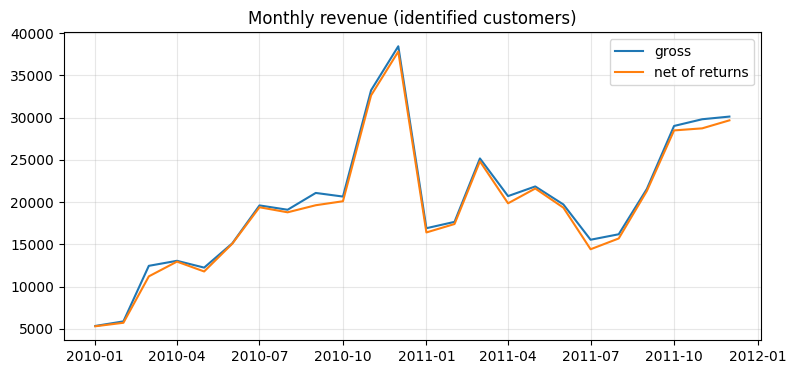

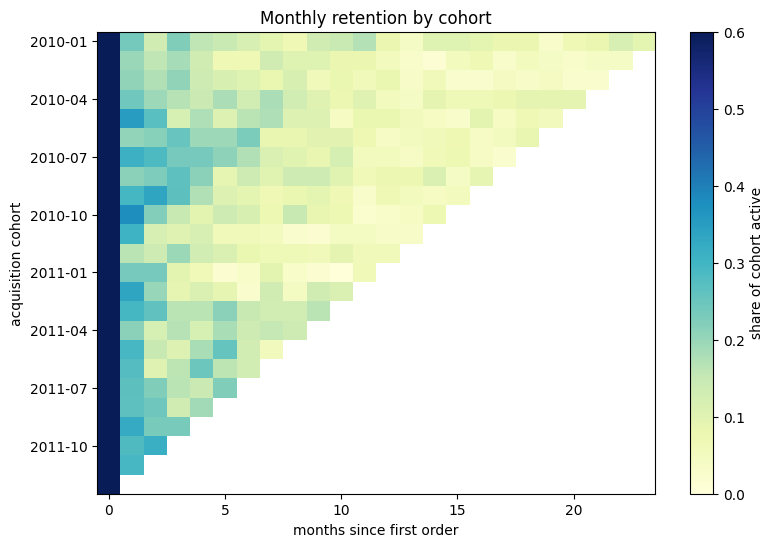

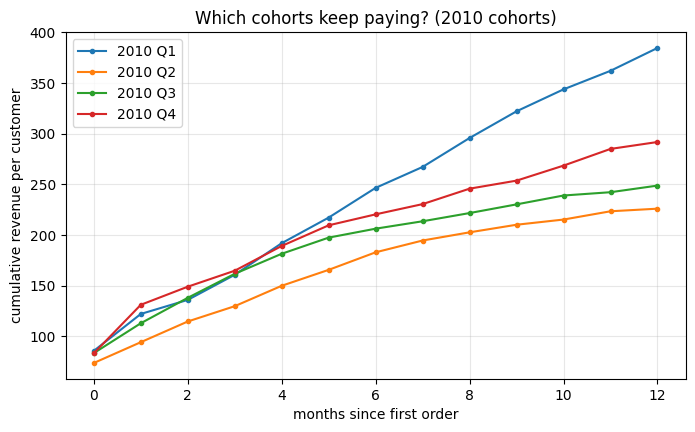

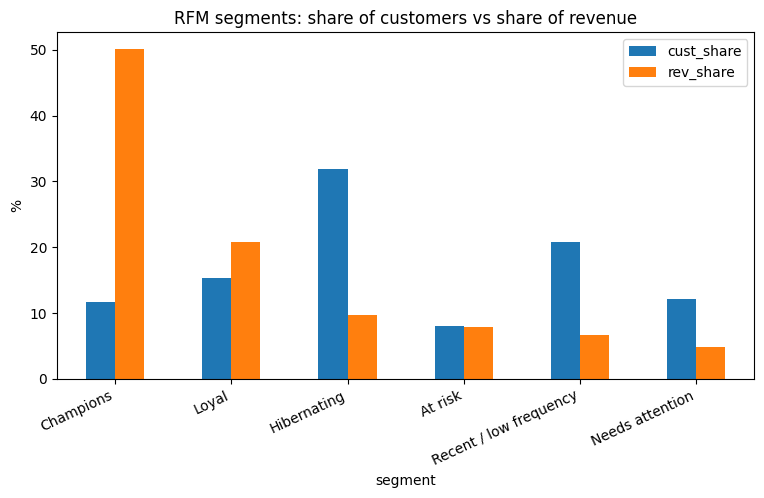

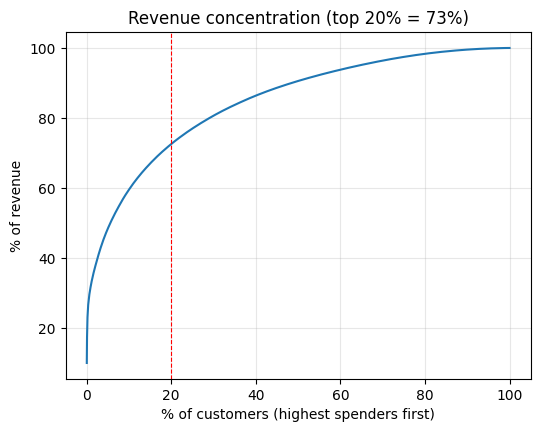

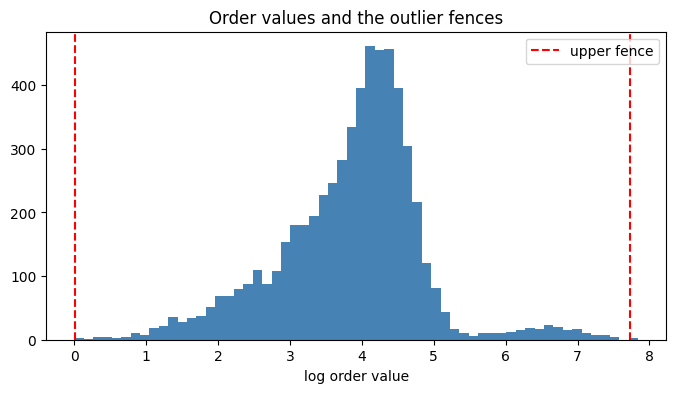

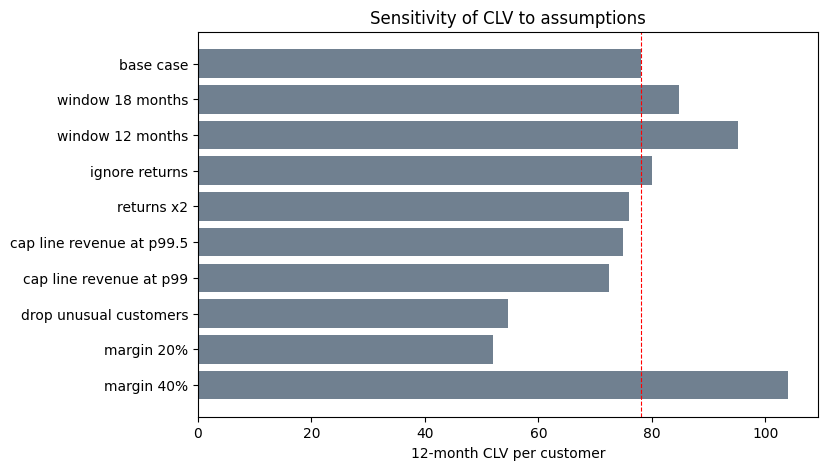

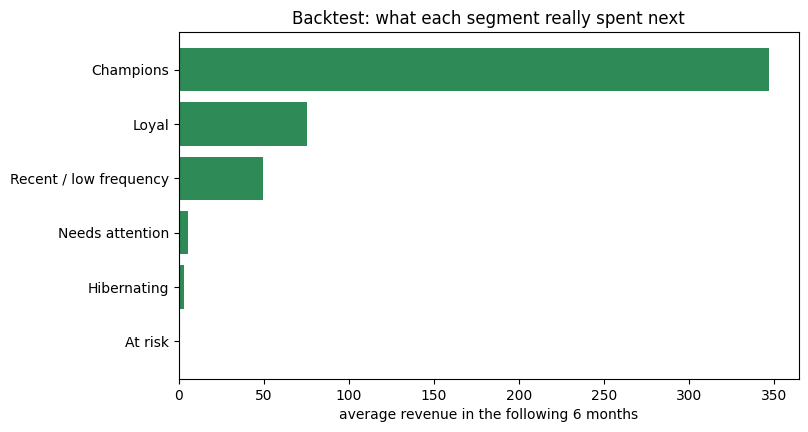


customers analysed: 1800, repeat rate 51.6%
average revenue per customer 260, 12-month CLV 78.1 at 30% margin
month-1 retention 26.8%, month-6 retention 11.5%
month-6 retention: Nov/Dec cohorts 7.0% vs other cohorts 12.0%
top 20% of customers = 72.6% of revenue
Champions: 11.7% of customers, 50.2% of revenue
unusual customers: 28, removing them changes mean revenue per customer by -30.2% and CLV by -29.9%
CLV range across sensitivity runs: 52.0 to 104.1

limitations:
- margin is assumed, there is no cost data
- first order in the file is treated as acquisition, so short windows mislabel old customers as new
- guest checkouts have no id and are left out of every customer metric
- retention is 'bought in the month', it does not separate churn from long gaps between orders
- the later cohorts have few observed months, so their curves are noisy

saved to outputs/


In [4]:
# Project 01 - Customer lifetime value and cohort retention
# Name: Prajjwal
# Admission No: 2026B15310503
#
# Works in VS Code ("# %%" lines are cells) and in Colab (%run clv_cohort_project.py).
# If data/online_retail_II.csv exists (UCI Online Retail II) it uses that,
# otherwise it makes a demo dataset with the same columns so everything still runs.

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
DATA_FILE = "data/online_retail_II.csv"
MARGIN = 0.30             # assumed gross margin, the dataset has no cost
DISC_MONTHLY = 0.01       # monthly discount rate for CLV
HORIZON = 12              # CLV horizon in months
HOLDOUT_MONTHS = 6        # months kept aside for the backtest
VALID_FROM = pd.Timestamp("2009-01-01")
VALID_TO = pd.Timestamp("2012-01-01")

os.makedirs("outputs", exist_ok=True)


def save(name):
    plt.savefig(f"outputs/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()


# %% 0. load data (or build a demo set)
def make_demo_data(n_cust=1800):
    r = np.random.default_rng(SEED)
    n_prod = 250
    codes = np.array([str(10000 + i) for i in range(n_prod)])
    prices = r.lognormal(1.0, 0.6, n_prod).round(2).clip(0.29)
    countries = np.array(["United Kingdom", "Germany", "France", "EIRE",
                          "Spain", "Netherlands", "Belgium", "Switzerland"])
    c_prob = [0.84, 0.04, 0.035, 0.025, 0.02, 0.015, 0.01, 0.015]
    season = np.array([0.8, 0.8, 0.9, 0.9, 0.95, 0.95, 0.9, 0.9, 1.1, 1.3, 1.6, 1.7])
    months = pd.date_range("2010-01-01", periods=24, freq="MS")
    last_day = pd.Timestamp("2011-12-31")
    rows = []
    inv_no = [500000]

    def new_order(cid, ctry, when, wholesale):
        inv_no[0] += 1
        inv = str(inv_no[0])
        k = int(r.integers(1, 9))
        idx = r.choice(n_prod, k, replace=False)
        qty = (r.poisson(3, k) + 1) * (12 if wholesale else 1)
        for i, q in zip(idx, qty):
            rows.append((inv, codes[i], f"ITEM {codes[i]}", int(q), when, prices[i], cid, ctry))
        if r.random() < 0.25:
            rows.append((inv, "POST", "POSTAGE", 1, when, 18.0, cid, ctry))
        # some customers send things back
        if not np.isnan(cid) and r.random() < 0.05:
            back = when + pd.Timedelta(days=int(r.integers(1, 20)))
            if back <= last_day:
                inv_no[0] += 1
                m = int(r.integers(1, k + 1))
                for i, q in list(zip(idx, qty))[:m]:
                    rows.append((f"C{inv_no[0]}", codes[i], f"ITEM {codes[i]}", -int(q), back,
                                 prices[i], cid, ctry))

    def random_time(month):
        d = int(r.integers(0, month.days_in_month))
        return month + pd.Timedelta(days=d, hours=int(r.integers(8, 18)), minutes=int(r.integers(0, 60)))

    ctry = r.choice(countries, n_cust, p=c_prob)
    w = np.linspace(1.3, 0.7, 24) * np.tile(season, 2)
    acq = r.choice(24, n_cust, p=w / w.sum())
    lam = r.gamma(1.2, 0.35, n_cust)
    churn = r.beta(2, 9, n_cust)
    whole = r.random(n_cust) < 0.02

    for c in range(n_cust):
        ch = churn[c]
        if months[acq[c]].month in (11, 12):      # christmas shoppers leave faster
            ch = min(ch * 1.6, 0.9)
        if whole[c]:
            ch *= 0.5
            lam[c] *= 1.5
        for m in range(acq[c], 24):
            n_ord = r.poisson(lam[c] * season[months[m].month - 1])
            if m == acq[c]:
                n_ord = max(n_ord, 1)
            for _ in range(n_ord):
                new_order(float(12000 + c), ctry[c], random_time(months[m]), whole[c])
            if r.random() < ch:
                break

    for _ in range(2500):                        # guest checkouts, no customer id
        new_order(np.nan, "United Kingdom", random_time(months[int(r.integers(0, 24))]), False)

    df = pd.DataFrame(rows, columns=["invoice", "stock_code", "description", "quantity",
                                     "invoice_date", "price", "customer_id", "country"])
    df = df.sort_values("invoice_date").reset_index(drop=True)

    # dirty rows, added on purpose
    df.loc[df.sample(25, random_state=2).index, "price"] = 0
    df.loc[df.sample(40, random_state=3).index, "description"] = np.nan
    neg = df.sample(20, random_state=4).copy()
    neg["invoice"] = [str(900000 + i) for i in range(20)]
    neg["quantity"] = -neg.quantity.abs()
    neg["customer_id"] = np.nan
    adj = pd.DataFrame({"invoice": [f"A90000{i}" for i in range(3)], "stock_code": "B",
                        "description": "Adjust bad debt", "quantity": 1,
                        "invoice_date": pd.Timestamp("2011-06-01"), "price": [-3000.0, -1200.0, -560.0],
                        "customer_id": np.nan, "country": "United Kingdom"})
    future = df.sample(3, random_state=6).copy()
    future["invoice_date"] = pd.Timestamp("2030-01-05")
    dup = df.sample(60, random_state=1)
    return pd.concat([df, neg, adj, future, dup], ignore_index=True)


if os.path.exists(DATA_FILE):
    raw = pd.read_csv(DATA_FILE, encoding="latin1")
    raw = raw.rename(columns={"Invoice": "invoice", "InvoiceNo": "invoice", "StockCode": "stock_code",
                              "Description": "description", "Quantity": "quantity",
                              "InvoiceDate": "invoice_date", "Price": "price", "UnitPrice": "price",
                              "Customer ID": "customer_id", "CustomerID": "customer_id",
                              "Country": "country"})
    raw["invoice_date"] = pd.to_datetime(raw.invoice_date, errors="coerce")
    print("using real file:", DATA_FILE)
else:
    raw = make_demo_data()
    print("no data file found, using the demo data")

raw["invoice"] = raw.invoice.astype(str)
raw["stock_code"] = raw.stock_code.astype(str)
print(raw.shape)
print(raw.head())

# %% 1. validation
log = []


def note(issue, n, treatment):
    log.append({"issue": issue, "rows": int(n), "treatment": treatment})


is_cancel = raw.invoice.str.startswith("C")
product_code = raw.stock_code.str.match(r"^\d{5}")

note("exact duplicate rows", raw.duplicated().sum(), "dropped")
note("invoice with more than one customer",
     raw.dropna(subset=["customer_id"]).groupby("invoice").customer_id.nunique().gt(1).sum(), "none found")
note("invoice with more than one timestamp",
     raw.groupby("invoice").invoice_date.nunique().gt(1).sum(), "rows outside date range dropped")
note("missing or invalid timestamp", raw.invoice_date.isna().sum(), "dropped")
note("timestamp outside 2009-2011 window", (~raw.invoice_date.between(VALID_FROM, VALID_TO)
                                           & raw.invoice_date.notna()).sum(), "dropped")
note("missing customer_id", raw.customer_id.isna().sum(), "kept as guest sales, left out of customer metrics")
note("missing description", raw.description.isna().sum(), "kept, not used in the analysis")
note("price <= 0", (raw.price <= 0).sum(), "dropped")
note("non-product stock codes (postage, fees, adjustments)", (~product_code).sum(), "dropped")
note("cancellation invoices (start with C)", is_cancel.sum(), "moved to a separate returns table")
note("cancellation with positive quantity", (is_cancel & (raw.quantity > 0)).sum(), "dropped")
note("negative quantity without C prefix", (~is_cancel & (raw.quantity < 0)).sum(), "dropped")

tx = raw.drop_duplicates()
tx = tx[tx.invoice_date.between(VALID_FROM, VALID_TO)]
tx = tx[(tx.price > 0) & tx.stock_code.str.match(r"^\d{5}")]
canc = tx.invoice.str.startswith("C")

returns = tx[canc & (tx.quantity < 0)].copy()
sales = tx[~canc & (tx.quantity > 0)].copy()
sales["revenue"] = sales.quantity * sales.price
returns["revenue"] = -returns.quantity * returns.price      # stored as a positive value

guest_share = sales.loc[sales.customer_id.isna(), "revenue"].sum() / sales.revenue.sum()
note("revenue share of guest rows", round(guest_share * 100, 1), "percent, reported only")

sales_c = sales.dropna(subset=["customer_id"]).copy()
returns_c = returns.dropna(subset=["customer_id"]).copy()
sales_c["customer_id"] = sales_c.customer_id.astype(int)
returns_c["customer_id"] = returns_c.customer_id.astype(int)

val_log = pd.DataFrame(log)
print("\n--- validation log ---")
print(val_log.to_string(index=False))
print(f"\nrows: raw {len(raw)} -> sales {len(sales_c)} + returns {len(returns_c)} (customers only)")

clean = pd.concat([sales_c.assign(kind="sale"), returns_c.assign(kind="return")], ignore_index=True)
clean.to_csv("outputs/clean_transactions.csv", index=False)

snapshot = sales_c.invoice_date.max().normalize() + pd.Timedelta(days=1)
start_all = sales_c.invoice_date.min().normalize()
print("observation window:", start_all.date(), "to", snapshot.date())


# %% 2. feature pipeline (RFM etc), reusable for any snapshot date
def build_features(sales, snapshot, start=None, returns=None):
    t = sales[sales.invoice_date < snapshot]
    if start is not None:
        t = t[t.invoice_date >= start]
    orders = t.groupby(["customer_id", "invoice"]).agg(
        order_date=("invoice_date", "min"),
        order_value=("revenue", "sum"),
        units=("quantity", "sum"),
    ).reset_index()

    f = orders.groupby("customer_id").agg(
        first_order=("order_date", "min"),
        last_order=("order_date", "max"),
        frequency=("invoice", "nunique"),
        monetary=("order_value", "sum"),
        aov=("order_value", "mean"),
        units=("units", "sum"),
    )
    f["recency"] = (snapshot - f.last_order).dt.days
    f["tenure"] = (snapshot - f.first_order).dt.days
    f["units_per_order"] = f.units / f.frequency
    f["orders_per_month"] = f.frequency / np.maximum(f.tenure / 30.44, 1)
    f["log_monetary"] = np.log1p(f.monetary)
    f["is_repeat"] = f.frequency >= 2

    f["returns"] = 0.0
    if returns is not None:
        rt = returns[(returns.invoice_date < snapshot)]
        if start is not None:
            rt = rt[rt.invoice_date >= start]
        f["returns"] = rt.groupby("customer_id").revenue.sum().reindex(f.index).fillna(0)
    f["net_monetary"] = f.monetary - f.returns

    # scores 1-5, 5 is best
    f["r_score"] = pd.qcut(f.recency.rank(method="first", ascending=False), 5, labels=False) + 1
    f["f_score"] = pd.cut(f.frequency, [0, 1, 2, 4, 8, np.inf], labels=False) + 1
    f["m_score"] = pd.qcut(f.monetary.rank(method="first"), 5, labels=False) + 1

    r, fr = f.r_score, f.f_score
    conds = [(r >= 4) & (fr >= 4), (r >= 3) & (fr >= 3), (r >= 4) & (fr <= 2),
             (r <= 2) & (fr >= 3), (r <= 2) & (fr <= 2)]
    names = ["Champions", "Loyal", "Recent / low frequency", "At risk", "Hibernating"]
    f["segment"] = np.select(conds, names, default="Needs attention")
    return f, orders


feat, orders = build_features(sales_c, snapshot, returns=returns_c)
feat["country"] = sales_c.groupby("customer_id").country.first()
print("\ncustomers:", len(feat))
print(feat[["recency", "frequency", "monetary", "aov", "returns"]].describe().round(1))


# %% 3. monthly cohorts and retention
def cohort_tables(s):
    s = s.assign(month=s.invoice_date.dt.to_period("M"))
    first = s.groupby("customer_id").month.min().rename("cohort")
    act = s.groupby(["customer_id", "month"]).revenue.sum().reset_index().join(first, on="customer_id")
    act["age"] = (act.month.dt.year - act.cohort.dt.year) * 12 + (act.month.dt.month - act.cohort.dt.month)

    size = first.value_counts().sort_index()
    last = s.month.max()
    max_age = np.array([(last.year - c.year) * 12 + (last.month - c.month) for c in size.index])
    ages = range(max_age.max() + 1)

    active = act.pivot_table(index="cohort", columns="age", values="customer_id", aggfunc="nunique")
    revenue = act.pivot_table(index="cohort", columns="age", values="revenue", aggfunc="sum")
    active = active.reindex(index=size.index, columns=ages).fillna(0)
    revenue = revenue.reindex(index=size.index, columns=ages).fillna(0)
    retention = active.div(size, axis=0)
    for i, a in enumerate(max_age):               # ages we cannot observe yet are NaN, not 0
        retention.iloc[i, a + 1:] = np.nan
    return act, size, retention, revenue


act, cohort_size, retention, cohort_rev = cohort_tables(sales_c)
print("\ncohorts:", len(cohort_size), "| avg month-1 retention: %.3f" % retention[1].mean())

# %% 4. revenue per customer, repeat rate, CLV
def estimate_clv(sales, returns, start, snapshot, ret_mult=1.0, cap=None, drop_ids=None,
                 margin=MARGIN, disc=DISC_MONTHLY, horizon=HORIZON):
    s = sales[(sales.invoice_date >= start) & (sales.invoice_date < snapshot)]
    rt = returns[(returns.invoice_date >= start) & (returns.invoice_date < snapshot)]
    if drop_ids is not None:
        s = s[~s.customer_id.isin(drop_ids)]
        rt = rt[~rt.customer_id.isin(drop_ids)]
    rt = rt[rt.customer_id.isin(s.customer_id.unique())]
    if cap is not None:
        s = s.assign(revenue=s.revenue.clip(upper=cap))

    act_, size_, ret_, _ = cohort_tables(s)
    R = ret_.to_numpy()
    n = size_.to_numpy()[:, None]
    seen = ~np.isnan(R)
    curve = list(np.where(seen, R * n, 0).sum(0) / np.where(seen, n, 0).sum(0))
    if len(curve) < horizon:        # window too short, extend with the average monthly decay
        ratios = [curve[k] / curve[k - 1] for k in range(2, len(curve)) if curve[k - 1] > 0]
        g = np.mean(ratios) if ratios else 0.8
        while len(curve) < horizon:
            curve.append(curve[-1] * g)
    curve = np.array(curve[:horizon])

    net = s.revenue.sum() - ret_mult * rt.revenue.sum()
    n_cust = s.customer_id.nunique()
    arpu = net / len(act_)                            # net revenue per active customer-month
    orders_per_cust = s.groupby("customer_id").invoice.nunique()
    return {
        "customers": n_cust,
        "repeat_rate": (orders_per_cust >= 2).mean(),
        "aov": s.groupby("invoice").revenue.sum().mean(),
        "rev_per_customer": net / n_cust,
        "arpu_month": arpu,
        "retention_m1": curve[1],
        "clv_12m": margin * arpu * (curve / (1 + disc) ** np.arange(horizon)).sum(),
    }


base = estimate_clv(sales_c, returns_c, start_all, snapshot)
print("\n--- base case ---")
for k, v in base.items():
    print(f"{k:18s} {v:,.3f}")

# simple closed form as a cross check: CLV = margin * arpu * (1+d) / (1+d-r)
r1 = retention.iloc[:, 1:4].stack().mean()
rough = MARGIN * base["arpu_month"] * (1 + DISC_MONTHLY) / (1 + DISC_MONTHLY - r1)
print("cross check with geometric formula (r=%.2f, infinite horizon): %.1f" % (r1, rough))

# %% 5. segments, robust summaries
def tmean(x, p=0.1):
    x = np.sort(x.to_numpy())
    k = int(len(x) * p)
    return x[k:len(x) - k].mean()


def summarise(df, by):
    out = df.groupby(by).agg(
        customers=("monetary", "size"),
        revenue=("monetary", "sum"),
        mean=("monetary", "mean"),
        trimmed_mean=("monetary", tmean),
        p25=("monetary", lambda x: x.quantile(0.25)),
        median=("monetary", "median"),
        p75=("monetary", lambda x: x.quantile(0.75)),
        p90=("monetary", lambda x: x.quantile(0.90)),
        p99=("monetary", lambda x: x.quantile(0.99)),
        avg_orders=("frequency", "mean"),
        median_recency=("recency", "median"),
    )
    out["cust_share"] = out.customers / out.customers.sum()
    out["rev_share"] = out.revenue / out.revenue.sum()
    return out.sort_values("revenue", ascending=False)


seg_summary = summarise(feat, "segment")
top_countries = feat.country.value_counts().head(6).index
country_summary = summarise(feat[feat.country.isin(top_countries)], "country")
print("\n--- RFM segments ---")
print(seg_summary.round(2).to_string())

sorted_rev = np.sort(feat.monetary.to_numpy())[::-1]
top20_share = sorted_rev[: int(len(sorted_rev) * 0.2)].sum() / sorted_rev.sum()
print("\ntop 20%% of customers make %.1f%% of revenue" % (top20_share * 100))

# backtest: features at a cutoff, then see what each segment actually spent afterwards
cutoff = snapshot - pd.DateOffset(months=HOLDOUT_MONTHS)
feat_cut, _ = build_features(sales_c, cutoff, returns=returns_c)
after = sales_c[sales_c.invoice_date >= cutoff]
after_ret = returns_c[returns_c.invoice_date >= cutoff]
feat_cut["future_orders"] = after.groupby("customer_id").invoice.nunique().reindex(feat_cut.index).fillna(0)
feat_cut["future_rev"] = (after.groupby("customer_id").revenue.sum().reindex(feat_cut.index).fillna(0)
                          - after_ret.groupby("customer_id").revenue.sum().reindex(feat_cut.index).fillna(0))
feat_cut["came_back"] = feat_cut.future_orders > 0

holdout = feat_cut.groupby("segment").agg(
    customers=("future_rev", "size"),
    came_back=("came_back", "mean"),
    mean_future=("future_rev", "mean"),
    median_future=("future_rev", "median"),
    p90_future=("future_rev", lambda x: x.quantile(0.9)),
    total_future=("future_rev", "sum"),
)
holdout["share_of_future_rev"] = holdout.total_future / holdout.total_future.sum()
holdout = holdout.sort_values("total_future", ascending=False)
print("\n--- backtest, next %d months by segment (cutoff %s) ---" % (HOLDOUT_MONTHS, cutoff.date()))
print(holdout.round(3).to_string())
rho_m = feat_cut.monetary.rank().corr(feat_cut.future_rev.rank())
rho_f = feat_cut.frequency.rank().corr(feat_cut.future_rev.rank())
print("rank correlation with future revenue: monetary %.2f, frequency %.2f" % (rho_m, rho_f))

# %% 6. unusual behaviour
lv = np.log(orders.order_value)
q1, q3 = lv.quantile([0.25, 0.75])
fence_hi, fence_lo = q3 + 3 * (q3 - q1), q1 - 3 * (q3 - q1)
orders["odd_order"] = (lv > fence_hi) | (lv < fence_lo)

x = feat.log_monetary
mad = (x - x.median()).abs().median()
feat["robust_z"] = 0.6745 * (x - x.median()) / mad
feat["odd_value"] = feat.robust_z.abs() > 3.5
feat["odd_units"] = feat.units_per_order > feat.units_per_order.quantile(0.99)
feat["odd_returns"] = (feat.returns / feat.monetary > 0.5) & (feat.frequency >= 2)
feat["unusual"] = feat.odd_value | feat.odd_units | feat.odd_returns

print("\nodd orders: %d (%.2f%% of orders, %.1f%% of revenue)" % (
    orders.odd_order.sum(), orders.odd_order.mean() * 100,
    orders.loc[orders.odd_order, "order_value"].sum() / orders.order_value.sum() * 100))
print("unusual customers:", int(feat.unusual.sum()),
      "| by value", int(feat.odd_value.sum()), "| by units", int(feat.odd_units.sum()),
      "| by returns", int(feat.odd_returns.sum()))

bad_ids = feat.index[feat.unusual]
with_all = estimate_clv(sales_c, returns_c, start_all, snapshot)
without = estimate_clv(sales_c, returns_c, start_all, snapshot, drop_ids=bad_ids)
keep = feat[~feat.unusual]
impact = pd.DataFrame({
    "all customers": [with_all["customers"], feat.monetary.sum(), feat.monetary.mean(), feat.monetary.median(),
                      with_all["aov"], with_all["repeat_rate"], with_all["clv_12m"]],
    "without unusual": [without["customers"], keep.monetary.sum(), keep.monetary.mean(), keep.monetary.median(),
                        without["aov"], without["repeat_rate"], without["clv_12m"]],
}, index=["customers", "total revenue", "mean revenue / customer", "median revenue / customer",
          "avg order value", "repeat rate", "CLV 12m"])
impact["change %"] = (impact["without unusual"] / impact["all customers"] - 1) * 100
print("\n--- impact of unusual customers ---")
print(impact.round(3).to_string())

# %% 7. sensitivity (window, returns, outliers, margin)
cap99 = sales_c.revenue.quantile(0.99)
cap995 = sales_c.revenue.quantile(0.995)
scen = [
    ("base case", "-", dict()),
    ("window 18 months", "window", dict(start=snapshot - pd.DateOffset(months=18))),
    ("window 12 months", "window", dict(start=snapshot - pd.DateOffset(months=12))),
    ("ignore returns", "returns", dict(ret_mult=0.0)),
    ("returns x2", "returns", dict(ret_mult=2.0)),
    ("cap line revenue at p99.5", "outliers", dict(cap=cap995)),
    ("cap line revenue at p99", "outliers", dict(cap=cap99)),
    ("drop unusual customers", "outliers", dict(drop_ids=bad_ids)),
    ("margin 20%", "margin", dict(margin=0.20)),
    ("margin 40%", "margin", dict(margin=0.40)),
]
rows = []
for name, grp, kw in scen:
    kw = dict(kw)
    st = kw.pop("start", start_all)
    res = estimate_clv(sales_c, returns_c, st, snapshot, **kw)
    rows.append({"scenario": name, "group": grp, **res})
sens = pd.DataFrame(rows)
sens["clv_change_%"] = (sens.clv_12m / sens.clv_12m.iloc[0] - 1) * 100
print("\n--- sensitivity ---")
print(sens.round(3).to_string(index=False))

# %% 8. charts
# 1 monthly revenue
m_gross = sales_c.groupby(sales_c.invoice_date.dt.to_period("M")).revenue.sum()
m_ret = returns_c.groupby(returns_c.invoice_date.dt.to_period("M")).revenue.sum()
m_net = m_gross - m_ret.reindex(m_gross.index).fillna(0)
plt.figure(figsize=(9, 4))
plt.plot(m_gross.index.to_timestamp(), m_gross.values, label="gross")
plt.plot(m_net.index.to_timestamp(), m_net.values, label="net of returns")
plt.title("Monthly revenue (identified customers)"); plt.legend(); plt.grid(alpha=0.3)
save("01_monthly_revenue")

# 2 retention heatmap
plt.figure(figsize=(9, 6))
plt.imshow(retention.to_numpy(), cmap="YlGnBu", aspect="auto", vmin=0, vmax=0.6)
plt.colorbar(label="share of cohort active")
plt.yticks(range(0, len(retention), 3), [str(c) for c in retention.index[::3]])
plt.xlabel("months since first order"); plt.ylabel("acquisition cohort")
plt.title("Monthly retention by cohort")
save("02_retention_heatmap")

# 3 cumulative revenue per customer, 2010 cohorts by quarter
c2010 = [c for c in cohort_rev.index if c.year == 2010]
qtr = np.array([f"2010 Q{c.quarter}" for c in c2010])
cum = cohort_rev.loc[c2010].cumsum(axis=1).iloc[:, :13]
per_cust = cum.groupby(qtr).sum().div(cohort_size.loc[c2010].groupby(qtr).sum(), axis=0)
plt.figure(figsize=(8, 4.5))
for q_name, row in per_cust.iterrows():
    plt.plot(row.index, row.values, marker="o", ms=3, label=q_name)
plt.xlabel("months since first order"); plt.ylabel("cumulative revenue per customer")
plt.title("Which cohorts keep paying? (2010 cohorts)"); plt.legend(); plt.grid(alpha=0.3)
save("03_cohort_cumulative_revenue")

# 4 segment share of customers vs revenue
s = seg_summary[["cust_share", "rev_share"]] * 100
s.plot.bar(figsize=(9, 4.5))
plt.ylabel("%"); plt.title("RFM segments: share of customers vs share of revenue")
plt.xticks(rotation=25, ha="right")
save("04_segment_shares")

# 5 pareto
cum_share = np.cumsum(sorted_rev) / sorted_rev.sum()
plt.figure(figsize=(6, 4.5))
plt.plot(np.arange(1, len(cum_share) + 1) / len(cum_share) * 100, cum_share * 100)
plt.axvline(20, color="red", ls="--", lw=0.8)
plt.xlabel("% of customers (highest spenders first)"); plt.ylabel("% of revenue")
plt.title("Revenue concentration (top 20%% = %.0f%%)" % (top20_share * 100)); plt.grid(alpha=0.3)
save("05_pareto")

# 6 order value distribution with fences
plt.figure(figsize=(8, 4))
plt.hist(lv, bins=60, color="steelblue")
plt.axvline(fence_hi, color="red", ls="--", label="upper fence")
plt.axvline(fence_lo, color="red", ls="--")
plt.xlabel("log order value"); plt.title("Order values and the outlier fences"); plt.legend()
save("06_order_value_outliers")

# 7 sensitivity
plt.figure(figsize=(8, 5))
plt.barh(sens.scenario[::-1], sens.clv_12m[::-1], color="slategray")
plt.axvline(sens.clv_12m.iloc[0], color="red", ls="--", lw=0.8)
plt.xlabel("12-month CLV per customer"); plt.title("Sensitivity of CLV to assumptions")
save("07_sensitivity")

# 8 backtest
hold = holdout.sort_values("mean_future")
plt.figure(figsize=(8, 4.5))
plt.barh(hold.index, hold.mean_future, color="seagreen")
plt.xlabel("average revenue in the following %d months" % HOLDOUT_MONTHS)
plt.title("Backtest: what each segment really spent next")
save("08_backtest")

# %% 9. export and findings
assumptions = pd.DataFrame({
    "assumption": ["gross margin", "monthly discount rate", "CLV horizon", "retention curve",
                   "returns", "guest sales", "customer identity", "outlier rule", "holdout"],
    "value": [f"{MARGIN:.0%} (dataset has no cost data)", f"{DISC_MONTHLY:.0%}", f"{HORIZON} months",
              "pooled across cohorts, extended with average decay if the window is short",
              "net revenue = sales - returns, matched to the same customer",
              "excluded from customer metrics", "customer_id is the real person",
              "modified z > 3.5 on log revenue, top 1% units per order, returns > 50% of spend",
              f"last {HOLDOUT_MONTHS} months"],
})
with pd.ExcelWriter("outputs/clv_cohort_tables.xlsx") as xw:
    val_log.to_excel(xw, sheet_name="validation_log", index=False)
    feat.to_excel(xw, sheet_name="rfm_customers")
    seg_summary.round(3).to_excel(xw, sheet_name="rfm_segments")
    country_summary.round(3).to_excel(xw, sheet_name="countries")
    retention.round(4).to_excel(xw, sheet_name="cohort_retention")
    cohort_rev.round(2).to_excel(xw, sheet_name="cohort_revenue")
    cohort_size.rename("customers").to_frame().to_excel(xw, sheet_name="cohort_size")
    holdout.round(3).to_excel(xw, sheet_name="backtest")
    impact.round(3).to_excel(xw, sheet_name="outlier_impact")
    sens.round(3).to_excel(xw, sheet_name="sensitivity", index=False)
    assumptions.to_excel(xw, sheet_name="assumptions", index=False)

ret6 = retention[6].dropna()
q4 = ret6[[c.month in (11, 12) for c in ret6.index]].mean()
rest = ret6[[c.month not in (11, 12) for c in ret6.index]].mean()
champ = seg_summary.loc["Champions"] if "Champions" in seg_summary.index else None

lines = [
    f"customers analysed: {len(feat)}, repeat rate {base['repeat_rate']:.1%}",
    f"average revenue per customer {base['rev_per_customer']:,.0f}, 12-month CLV {base['clv_12m']:,.1f} at {MARGIN:.0%} margin",
    f"month-1 retention {retention[1].mean():.1%}, month-6 retention {ret6.mean():.1%}",
    f"month-6 retention: Nov/Dec cohorts {q4:.1%} vs other cohorts {rest:.1%}",
    f"top 20% of customers = {top20_share:.1%} of revenue",
]
if champ is not None:
    lines.append(f"Champions: {champ.cust_share:.1%} of customers, {champ.rev_share:.1%} of revenue")
lines += [
    f"unusual customers: {int(feat.unusual.sum())}, removing them changes mean revenue per customer by "
    f"{impact.loc['mean revenue / customer', 'change %']:.1f}% and CLV by {impact.loc['CLV 12m', 'change %']:.1f}%",
    f"CLV range across sensitivity runs: {sens.clv_12m.min():,.1f} to {sens.clv_12m.max():,.1f}",
    "",
    "limitations:",
    "- margin is assumed, there is no cost data",
    "- first order in the file is treated as acquisition, so short windows mislabel old customers as new",
    "- guest checkouts have no id and are left out of every customer metric",
    "- retention is 'bought in the month', it does not separate churn from long gaps between orders",
    "- the later cohorts have few observed months, so their curves are noisy",
]
open("outputs/findings.txt", "w").write("\n".join(lines))
print("\n" + "\n".join(lines))
print("\nsaved to outputs/")